In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
%matplotlib inline
import random
from tqdm.notebook import tqdm
import seaborn as sns
from qpsolvers import solve_qp
from itertools import product
import pandas as pd

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.
WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


Incompatible version of wgpu:
    Detected 0.15.3.post97+g8a0b267, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

## Dataset
First prepare the dataset for clustering.

In [3]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: float,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg,
        interp_factor: int = 2,
        firing_prop: float = 0.005,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: float

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor))

    x = 0
    a = 0.7

    b = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [4]:
def update_weight(W, M, x_t, y_t, y_hat):
    """ Update weight matrix of W and M.
    Equation (8) in the original paper.
    """
    y_dim = y_t.shape[0]
    y_hat += (y_t * y_t)
    
    # (3,1) x (1,2) = (3,2)
    dW = y_t[:,np.newaxis].dot( x_t[np.newaxis,:] - (W.T.dot(y_t[:,np.newaxis])).T)
    #dW = dW / y_hat[:,np.newaxis]
    # (3, 2)
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            W[i] += (dW[i] / y_hat[i])
    
    # (3,1) x (1,3) = (3,3)
    dM = y_t[:,np.newaxis].dot( y_t[np.newaxis,:] - (M.T.dot(y_t[:,np.newaxis])).T)
    #dM = dM / y_hat[:,np.newaxis]
    
    # Set diagonal elements to zero
    for i in range(M.shape[0]):
        dM[i,i] = 0.0
    
    for i in range(y_dim):
        if y_hat[i] > 0:
            M[i] += (dM[i] / y_hat[i])

In [5]:
def adjust_y_i(y_t, x_t, y_index, lambd=0.5):
    """ If the node in y_t is not active previously, adjust it.
    Equation (5) in the original paper.
    """
    # y_t = (3,)
    # x_t = (2,)
    
    y_dim = y_t.shape[0]
    
    # Calculate squree L2 norm of x_t
    x_norm_sq = x_t.dot(x_t)    
    y_t_sqs = y_t * y_t # (3,)
    
    y_t_adj = np.empty_like(y_t)
    
    d_i = x_norm_sq - (np.sum(y_t_sqs) - y_t_sqs[y_index])
    d_i_sq = d_i * d_i
    if d_i_sq <= lambd:
        return 0.0
    else:
        if d_i < 0.0:
            print("d_i was negative: {}".format(d_i))
            d_i = 0.0
    return np.sqrt(d_i)

In [60]:
def sim_matching_init(X_init, k, error) -> tuple[np.ndarray, np.ndarray, int]:
    """
    Returns
    -------
        W, M, n_iter
    """
    cov = X_init.T @ X_init
    XTX = cov / np.linalg.norm(cov, ord="fro")
    
    T = XTX.shape[0]

    eta = 1e-1
    
    Y = (np.random.randn(k, T) / np.sqrt(T)).clip(0)

    for n_iter in range(25_000):
        Y_old = Y
        Y = Y + eta * Y @ (XTX - Y.T @ Y)
        
        zeroed = Y.sum(axis=1) == 0.0
        Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
        
        Y = Y.clip(0)
    
        er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
    
        if er < error:
            break
            
    W = Y @ X_init.T
    M = Y @ Y.T

    return W, M, n_iter

In [61]:
def solve_yt(x_t, Wt, Mt, k):
    return solve_qp(
        (Mt + Mt.T) / 2,
        -Wt @ x_t,
        lb=np.zeros(k),
        solver="cvxopt"
    )

In [82]:
p_n_components = [2, 3, 5, 10, 30]
p_noise = [0.1, 0.25, 0.5]
p_firing_prop = [0.05, 0.01]
p_T_init = [100, 500, 750]
p_error_init = [1e-3, 1e-5]
p_random_iter = list(range(1, 11))

params = [
    p_n_components, 
    p_noise, 
    p_firing_prop,
    p_T_init,
    p_error_init,
    p_random_iter
]

In [83]:
def run_sample(n_components, noise, firing_prop, T_init, error_init, random_iter) -> dict:
    result = {
        "X": None,
        "W": None,
        "M": None,
        "Y": None,
        "random_iter": random_iter,
    }

    result["n_components"] = n_components
    result["noise"] = noise
    result["T_init"] = T_init
    result["error_init"] = error_init
    result["firing_prop"] = firing_prop
    result["random_iter"] = random_iter

    k = n_components
    
    np.random.seed(random_iter)
    X, _ = generate_data(
        n_timepoints=5_000,
        n_components=n_components,
        noise=noise,
        n_pixels=5,
        n_pixels_bg=0,
        interp_factor=1,
        firing_prop=firing_prop,
    )

    T = X.shape[1]
    
    # initialization offline with T_init
    W, M, n_iter = sim_matching_init(X[:, :T_init], k, error_init)

    result["W"] = W.copy()
    result["M"] = M.copy()
    result["init_n_iter"] = n_iter
    
    F = np.linalg.inv(M) @ W
    F /= F.sum(axis=1)[:, None]
    
    result["F_off_diag_norm"] = np.linalg.norm((F @ F.T)[~np.eye(k, dtype=bool)])

    F_norm_sum = F / F.sum(axis=0)
    F_norm_max = F / F.max(axis=0)

    # 5 is n_pixels per component
    result["F_sum_norm_diff_I"] = np.linalg.norm(((F_norm_sum @ F_norm_sum.T) / 5) - np.eye(k), ord="fro")

    ideal = np.concatenate([[i] * 5 for i in range(k)])
    n_wrong = np.count_nonzero(ideal - np.sort(F.argmax(axis=0)))
    result["n_incorrectly_clustered_pixels"] = n_wrong
    result["percent_incorrectly_clustered_pixels"] = n_wrong / X.shape[0]
    
    Y = np.zeros((k, T))
    # run online for rest of T
    for t in range(T):
        x_t = X[:, t]
        Y[:, t] = solve_yt(x_t, W, M, k=k)
        
    result["X"] = X.copy()
    result["Y"] = Y.copy()

    X_sorted = X[F.argmax(axis=0).argsort()]
    X_mean = np.vstack([a.mean(axis=0) for a in np.split(X_sorted, k, axis=0)]).clip(0)
    
    Y /= Y.max()
    Y *= X.max()
    XmY = X_mean - Y
    
    result["X_mean - Y"] = XmY
    result["(X_mean - Y)_fro"] = np.linalg.norm(X_mean - Y, ord="fro") / k
    
    return result

In [84]:
from joblib import Parallel, delayed

In [85]:
results = list()

In [86]:
variants = tuple(product(*params))
len(variants)

1800

In [ ]:
runner = Parallel(n_jobs=10, verbose=10)

results = runner(
    delayed(run_sample)(*args) for args in variants
)

[Parallel(n_jobs=10)]: Using backend LokyBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done   5 tasks      | elapsed:    2.2s


In [77]:
df = pd.DataFrame(results)

In [78]:
df

,X,W,M,Y,random_iter,n_components,noise,T_init,error_init,firing_prop,init_n_iter,F_off_diag_norm,F_sum_norm_diff_I,n_incorrectly_clustered_pixels,percent_incorrectly_clustered_pixels,X_mean - Y,(X_mean - Y)_fro
0,"[[-0.07617771181350987, 0.10543316045038209, 1...","[[1.7697680194730605, 1.7059795696962872, 1.61...","[[0.8220909747730505, 0.29261358347960725], [0...","[[6.360351151665181e-09, 1.346196181355852, 28...",1,2,0.1,100,0.00100,0.05,1366,0.003323,0.052895,0,0.000000,"[[-2.2741403672663215e-10, 0.01483218259871373...",0.977296
1,"[[-0.07617771181350987, 0.10543316045038209, 1...","[[1.771933672975833, 1.7081722969128357, 1.615...","[[0.8226606633388815, 0.2922030669291264], [0....","[[6.343300573439607e-09, 1.3452009711878659, 2...",1,2,0.1,100,0.00001,0.05,2205,0.003323,0.050465,0,0.000000,"[[-2.2679262708380932e-10, 0.01487026168925578...",0.974083
2,"[[-0.07617771181350987, 0.10543316045038209, 1...","[[7.831446652154116, 7.921549375485471, 7.7411...","[[0.7384912767240632, 0.22479409259092287], [0...","[[8.128712805655726e-10, 1.0668007155743534e-0...",1,2,0.1,500,0.00100,0.05,517,0.004879,0.038022,0,0.000000,"[[-1.6183599838088323e-11, -2.1239126415967536...",0.943608
3,"[[-0.07617771181350987, 0.10543316045038209, 1...","[[7.83249815926035, 7.922593854247841, 7.74221...","[[0.7386817091202217, 0.22472965535359418], [0...","[[8.084486678874379e-10, 1.0694483336579042e-0...",1,2,0.1,500,0.00001,0.05,849,0.004875,0.037547,0,0.000000,"[[-1.6095625162652714e-11, -2.1291938737881433...",0.943359
4,"[[-0.07617771181350987, 0.10543316045038209, 1...","[[9.054043373250527, 9.19732943299987, 9.00701...","[[0.74347906477783, 0.20257526501430628], [0.2...","[[9.307540972196801e-10, 9.218703381563049e-08...",1,2,0.1,750,0.00100,0.05,442,0.004994,0.037849,0,0.000000,"[[-1.6122098411450178e-11, -1.5968217984481137...",0.939930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,"[[-0.8875494696113049, 0.6953666042150574, 0.4...","[[0.1903573793170601, -0.09657445552122955, -0...","[[0.11173452439604496, 0.009944847480327926, 0...","[[5.006381599123502e-07, 2.2670041887785597e-0...",1,30,0.5,100,0.00001,0.01,24999,46.555720,1126.890847,145,0.966667,"[[-8.26869891289067e-09, -3.7442561459065975e-...",2.481295
176,"[[-0.8875494696113049, 0.6953666042150574, 0.4...","[[0.04233746975709625, -0.05287243947640156, 0...","[[0.06812989793626484, 0.0024176510601127913, ...","[[7.749067722804886e-08, 5.975364718697314e-09...",1,30,0.5,500,0.00100,0.01,24999,7.594307,22810.815297,127,0.846667,"[[-8.242382256124087e-10, -6.355763285732834e-...",2.710615
177,"[[-0.8875494696113049, 0.6953666042150574, 0.4...","[[0.04233746975709625, -0.05287243947640156, 0...","[[0.06812989793626484, 0.0024176510601127913, ...","[[7.749067722804886e-08, 5.975364718697314e-09...",1,30,0.5,500,0.00001,0.01,24999,7.594307,22810.815297,127,0.846667,"[[-8.242382256124087e-10, -6.355763285732834e-...",2.710615
178,"[[-0.8875494696113049, 0.6953666042150574, 0.4...","[[0.1738312525280386, -0.0918155477460372, -0....","[[0.06507229131428596, 0.00945909035130946, 0....","[[1.948037922348869e-07, 19.382156135483523, 1...",1,30,0.5,750,0.00100,0.01,24999,12.800379,1352.416476,139,0.926667,"[[-1.7529702721651516e-09, -0.0598201776836722...",2.802024


In [17]:
df["firing_prop"] = df["firing_prop"].astype(str)

In [18]:
df[df["n_components"] == 3]

,X,W,M,Y,random_iter,n_components,init_method,firing_prop,mean_center,W_init,X_mean,x_cov,y_cov,diff
12,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.05391927786163472, 0.05487168422132714, 0....","[[0.0, 0.19286914131354435, 0.1614083701635221...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,block_diag,0.05,False,"[[1.0, 1.0575795287961374, 1.0, 1.205593537838...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[1.1989227822493433e-05, 8.042916179334572e-0...","[[4.4168525385327686e-05, 1.8963283232671418e-...",0.071513
13,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.0007175084636905909, 0.0016497055054101992...","[[0.0, 0.07110892799571197, 0.1055388883116250...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,block_diag,0.01,False,"[[1.0, 1.0575795287961374, 1.0, 1.205593537838...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[7.066910944034392e-05, 4.740803428812473e-05...","[[0.0002482595472853833, 0.0001065875772241966...",0.075054
14,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[-0.012850341972244444, -0.007134551655734341...","[[0.0, 0.047897709775991504, 0.110171473223769...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,block_diag,0.005,False,"[[1.0, 1.0575795287961374, 1.0, 1.205593537838...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[0.00013676282950395908, 9.174669048204005e-0...","[[0.0004847123356637121, 0.0002081060489878629...",0.092813
15,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.16140845333689477, 0.22625768863955628, 0....","[[0.0, -0.014166104923418868, 0.18607806146009...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,block_diag,0.001,False,"[[1.0, 1.0575795287961374, 1.0, 1.205593537838...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[0.0004680426836496361, 0.0003139841972042810...","[[0.002079993944690739, 0.0008930231188681406,...",0.240457
16,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.015766910355487943, 0.014953628798585236, ...","[[0.0, 0.24999428881053726, 0.0287412981673620...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,zeros,0.05,False,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[1.1989227822493433e-05, 8.042916179334572e-0...","[[4.894949624198604e-05, 2.1015941855322142e-0...",0.150183
17,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.0717771277223812, 0.06759966468757118, 0.0...","[[0.0, 0.006228075238725622, 0.129372397040516...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,zeros,0.01,False,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[7.066910944034392e-05, 4.740803428812473e-05...","[[0.0002811046814841263, 0.0001206892837491958...",0.172398
18,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.06022899976621907, 0.05179433165886205, 0....","[[0.0, 0.015316288138225833, 0.122787116216534...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,zeros,0.005,False,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[0.00013676282950395908, 9.174669048204005e-0...","[[0.000562626831796965, 0.00024155780326799505...",0.192022
19,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.3782559497749844, 0.3497588416797026, 0.23...","[[0.0, 0.1131443962833261, 0.08191156983767078...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,zeros,0.001,False,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[0.0004680426836496361, 0.0003139841972042810...","[[0.002101947138029708, 0.0009024484872615072,...",0.238095
20,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.24959325807804786, 0.24959894094083895, 0....","[[0.0, 0.004301262271170483, 0.217712270041840...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,random,0.05,False,"[[0.5488135039273248, 0.7151893663724195, 0.60...

In [19]:
from ipywidgets import HBox, Label, VBox, Layout

In [20]:
sns.heatmap(df_n_0.iloc[0]["W_init"], cmap="viridis")

NameError: name 'df_n_0' is not defined

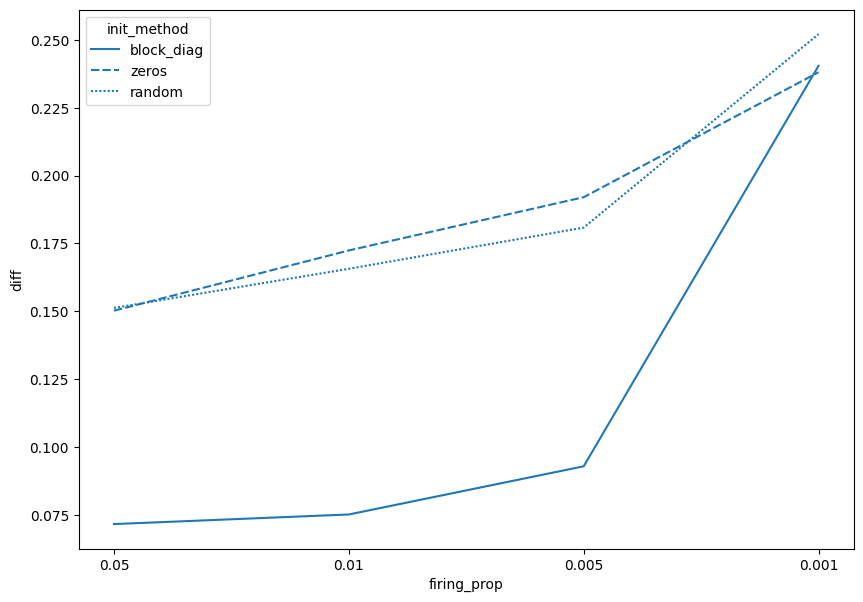

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

RFBOutputContext()

In [29]:
fig = plt.figure(figsize=(10, 7))

df_n = df[df["n_components"] == 3]
df_n_0 = df_n[df_n["random_iter"] == 0]

sns.lineplot(
    data=df_n_0,
    x="firing_prop",
    y="diff",
    style="init_method",
    # err_style="bars",
    # hue="mean_center"
)
plt.show()

widgets = list()
for init_method in df_n_0["init_method"].unique():
    widgets_v = list()
    Ws, names = zip(*[(r["W"], r["firing_prop"]) for _, r in df_n_0[df_n_0["init_method"] == init_method].iterrows()])
    
    widgets_v.append(Label(value=init_method, layout=Layout(display="flex", justify_content="center", width="100%", border="solid")))
    iw = fpl.ImageWidget(list(Ws), names=names, cmap="viridis", figure_kwargs={"shape": (2, 2), "size": (700, 700)}).show(maintain_aspect=False)
    widgets_v.append(iw)
    widgets.append(VBox(widgets_v))

HBox(widgets)

In [31]:
r = df[df["n_components"] == 3].iloc[5]
r

X               [[7.528544631648396, 1.6181789564382785, 4.237...
W               [[0.0717771277223812, 0.06759966468757118, 0.0...
M               [[0.0, 0.006228075238725622, 0.129372397040516...
Y               [[23.98667651700602, 0.0, 0.0], [10.2984226128...
random_iter                                                     0
n_components                                                    3
init_method                                                 zeros
firing_prop                                                  0.01
mean_center                                                 False
W_init          [[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...
X_mean          [[1.786219653030371, 0.0, 0.0, 1.4724327896642...
x_cov           [[7.066910944034392e-05, 4.740803428812473e-05...
y_cov           [[0.0002811046814841263, 0.0001206892837491958...
diff                                                     0.172398
Name: 17, dtype: object

<Axes: >

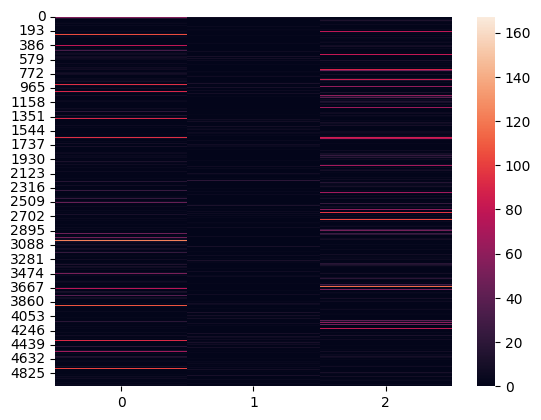

In [33]:
sns.heatmap(r["Y"])

<Axes: >

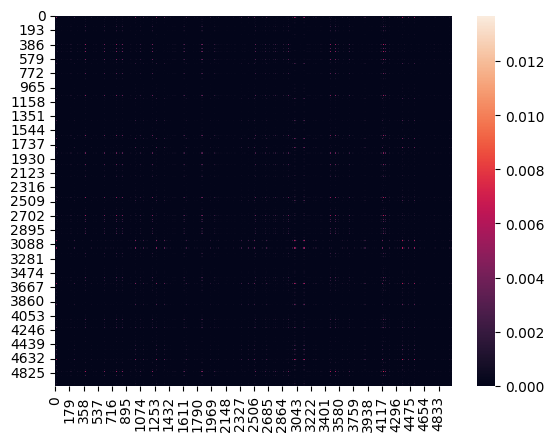

In [35]:
sns.heatmap(r["y_cov"])

<Axes: >

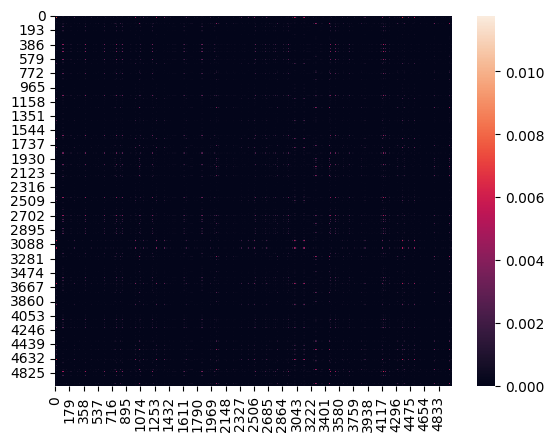

In [36]:
sns.heatmap(r["x_cov"])

<Axes: >

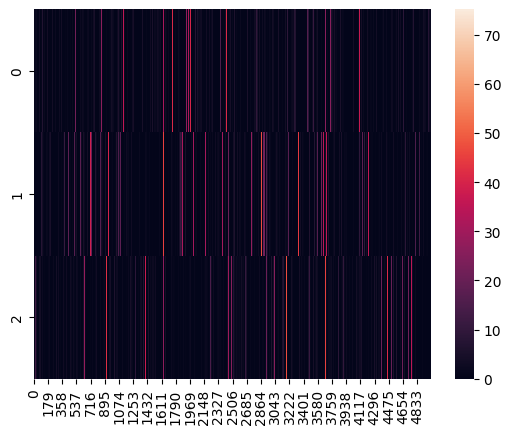

In [34]:
sns.heatmap(r["X_mean"])

In [77]:
df_n

,X,W,M,Y,random_iter,n_components,init_method,firing_prop,W_init,X_mean,x_cov,y_cov,diff
60,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.05391927786163472, 0.05487168422132714, 0....","[[0.0, 0.19286914131354435, 0.1614083701635221...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,block_diag,0.05,"[[1.0, 1.0575795287961374, 1.0, 1.205593537838...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[0.9999999999999999, 0.2691032613148173, 0.28...","[[1.0000000000000018, 0.27257448210247665, 0.2...",0.038753
61,"[[0.5157134691598118, 4.60819193915578, -5.801...","[[0.4440014642495154, 0.43969297838660215, 0.4...","[[0.0, 0.14814472676940227, 0.2372257508298957...","[[25.636441526779528, 0.0, 0.0], [9.2648992568...",1,3,block_diag,0.05,"[[1.0859313347587398, 1.3248938760101145, 1.0,...","[[0.0, 1.016048630336525, 51.13367405510532, 3...","[[1.0, 0.26294938909048277, 0.2989836286876982...","[[1.0000000000000007, 0.204591053118397, 0.275...",0.041398
62,"[[2.399741663378462, 5.836550364523815, -2.751...","[[0.42550445960494543, 0.42551341748540467, 0....","[[0.0, 0.17986900627723937, 0.2755011229032406...","[[22.39540508268852, 0.0, 0.0], [0.0, 23.71790...",2,3,block_diag,0.05,"[[1.3206861226081577, 1.0, 1.0509119668809819,...","[[3.637143465339019, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[1.0, 0.28267566838186886, 0.2489926629690921...","[[1.0000000000000002, 0.3355015938616893, 0.30...",0.074749
63,"[[-1.1945727079190227, 8.203794347715846, 5.26...","[[0.004362890340017648, 0.008220103531927364, ...","[[0.0, 0.16342169384414024, 0.2873996406084558...","[[15.764186143703567, 0.0, 0.0], [0.3184145219...",3,3,block_diag,0.05,"[[1.2377377202393443, 1.182731328931268, 1.162...","[[3.1864877758033154, 0.8929328594311559, 1.23...","[[1.0, 0.281181547070457, 0.2588417759621294],...","[[1.0000000000000009, 0.20458981937779483, 0.2...",0.038839
64,"[[-0.2709430255565031, 8.800307523053963, 3.92...","[[0.1260094512595386, 0.12486673682168951, 0.1...","[[0.0, 0.1643325579931047, 0.16805164921859597...","[[16.486659532312814, 0.0, 0.0], [0.2729438904...",4,3,block_diag,0.05,"[[1.0, 1.0, 1.0, 1.0036315280298884, 1.0, 0.02...","[[1.7248618514035055, 0.0, 0.0, 0.0, 0.0, 0.0,...","[[0.9999999999999999, 0.26085903555147316, 0.2...","[[1.0, 0.30072370550776745, 0.2532068649226914...",0.060346
65,"[[7.528544631648396, 1.6181789564382785, 4.237...","[[0.0007175084636905909, 0.0016497055054101992...","[[0.0, 0.07110892799571197, 0.1055388883116250...","[[23.98667651700602, 0.0, 0.0], [10.2984226128...",0,3,block_diag,0.01,"[[1.0, 1.0575795287961374, 1.0, 1.205593537838...","[[1.786219653030371, 0.0, 0.0, 1.4724327896642...","[[0.9999999999999999, 0.13781099714465328, 0.1...","[[1.0000000000000009, 0.0860393616298619, 0.10...",0.032021
66,"[[0.5157134691598118, 4.60819193915578, -5.801...","[[-0.0851944042676325, -0.04363075631577887, -...","[[0.0, -0.020044787379970865, 0.75481218975060...","[[25.636441526779528, 0.0, 0.0], [9.2648992568...",1,3,block_diag,0.01,"[[1.0859313347587398, 1.3248938760101145, 1.0,...","[[0.0, 1.016048630336525, 51.13367405510532, 3...","[[1.0000000000000002, 0.17905561156095032, 0.1...","[[1.0000000000000002, 0.06743075188475767, 0.4...",0.152368
67,"[[2.399741663378462, 5.836550364523815, -2.751...","[[0.27481449590133, 0.26784928827461396, 0.257...","[[0.0, 0.007695629410343081, 0.129306124368572...","[[22.39540508268852, 0.0, 0.0], [0.0, 23.71790...",2,3,block_diag,0.01,"[[1.3206861226081577, 1.0, 1.0509119668809819,...","[[3.637143465339019, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[0.9999999999999998, 0.12948404344273048, 0.1...","[[1.0000000000000007, 0.036605392570181146, 0....",0.058160
68,"[[-1.1945727079190227, 8.203794347715846, 5.26...","[[0.2577874626971499, 0.27825607425322063, 0.2...","[[0.0, 0.022989111612143665, 0.109427511915142...","[[15.764186143703567, 0.0, 0.0], [0.3184145219...",3,3,block_diag,0.01,"[[1.2377377202393443, 1.182731328931268, 1.162...","[[3.1864877758033154, 0.8929328594311559, 1

In [78]:
r1 = df.iloc[60]
r1

X               [[7.528544631648396, 1.6181789564382785, 4.237...
W               [[0.05391927786163472, 0.05487168422132714, 0....
M               [[0.0, 0.19286914131354435, 0.1614083701635221...
Y               [[23.98667651700602, 0.0, 0.0], [10.2984226128...
random_iter                                                     0
n_components                                                    3
init_method                                            block_diag
firing_prop                                                  0.05
W_init          [[1.0, 1.0575795287961374, 1.0, 1.205593537838...
X_mean          [[1.786219653030371, 0.0, 0.0, 1.4724327896642...
x_cov           [[0.9999999999999999, 0.2691032613148173, 0.28...
y_cov           [[1.0000000000000018, 0.27257448210247665, 0.2...
diff                                                     0.038753
Name: 60, dtype: object

<Axes: >

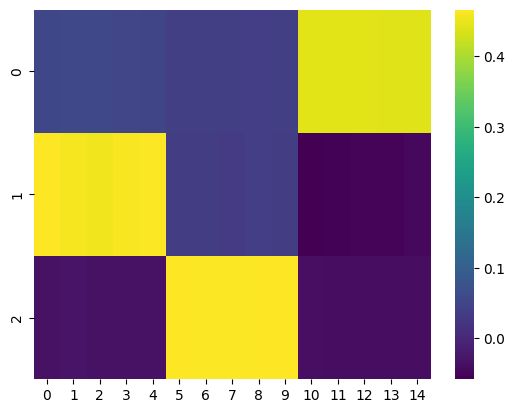

In [79]:
sns.heatmap(r1["W"], cmap="viridis")

In [283]:
r2 = df.iloc[207]
r2

X               [[-1.1945727079190227, 8.203794347715846, 5.26...
W               [[0.004360858942343541, 0.008133821347649554, ...
M               [[0.0, 0.16427056610211604, 0.2719110529744509...
Y               [[15.764186143703567, 0.0, 0.0], [0.3184145219...
random_iter                                                     3
n_components                                                    3
init_method                                                random
firing_prop                                                  0.05
mean_center                                                 False
W_init          [[0.5488135039273248, 0.7151893663724195, 0.60...
X_mean          [[3.1864877758033154, 0.8929328594311559, 1.23...
x_cov           [[0.4851907310781859, 0.14258692178151164, 0.1...
y_cov           [[0.43607760309735666, 0.10048616300050002, 0....
diff                                                     0.029027
Name: 207, dtype: object

<Axes: >

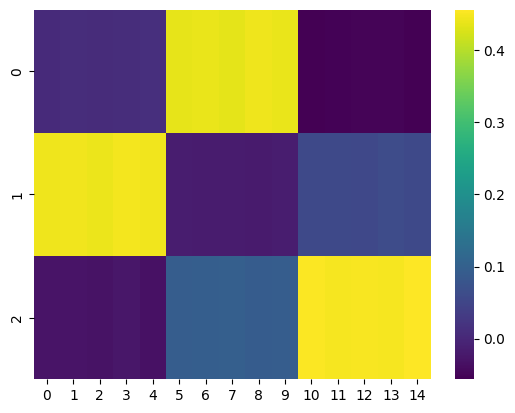

In [284]:
sns.heatmap(r2["W"], cmap="viridis")

<Axes: >

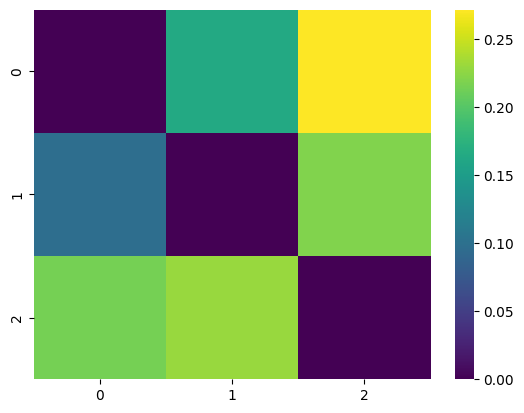

In [297]:
sns.heatmap(r2["M"], cmap="viridis")

<Axes: >

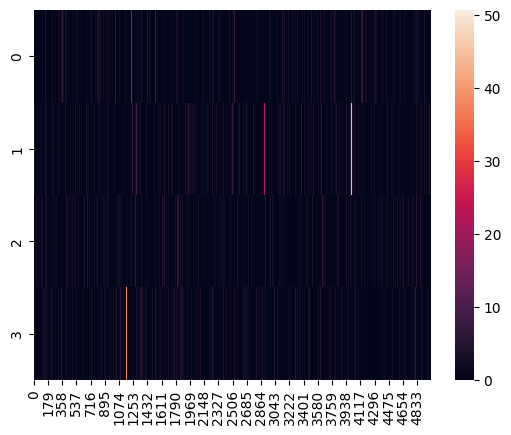

In [298]:
sns.heatmap(X_mean @ )

<Axes: >

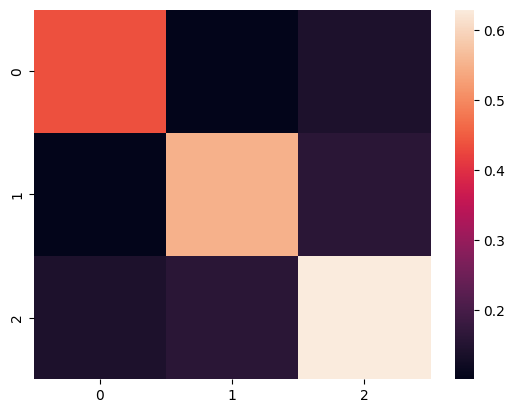

In [278]:
sns.heatmap(r2["y_cov"])

<Axes: >

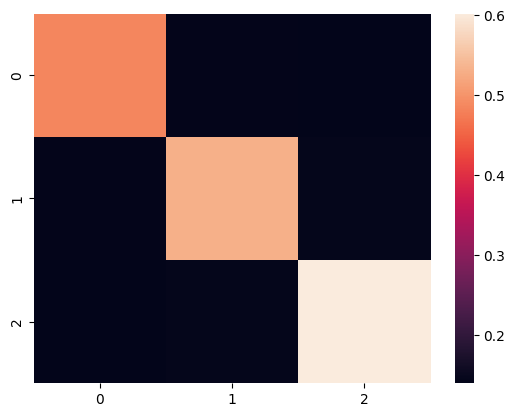

In [279]:
sns.heatmap(r2["x_cov"])

<Axes: >

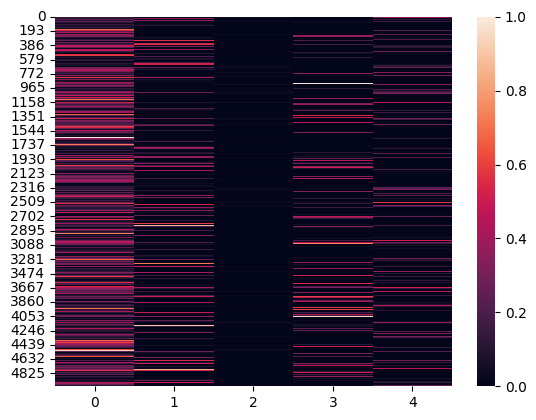

In [209]:
Y = r410["Y"]
sns.heatmap(Y)

In [202]:
def correlation(M):
    n_rows = M.shape[0]
    out = np.zeros((n_rows, n_rows))
    for i in range(n_rows):
        for j in range(n_rows):
            u = M[i]
            v = M[j]
    
            corr = (u.T @ v) / (np.linalg.norm(u, ord=2) * np.linalg.norm(v, ord=2))
            
            out[i, j] = corr
    return out

<Axes: >

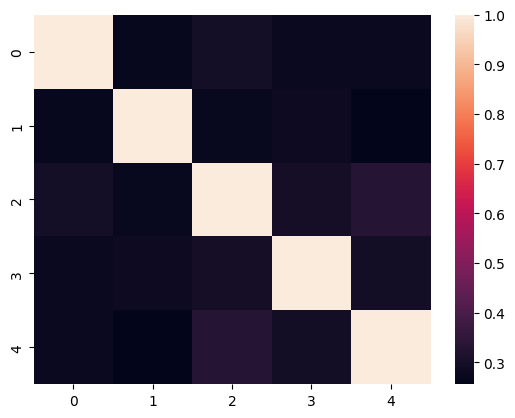

In [203]:
sns.heatmap(correlation(X_mean))

<Axes: >

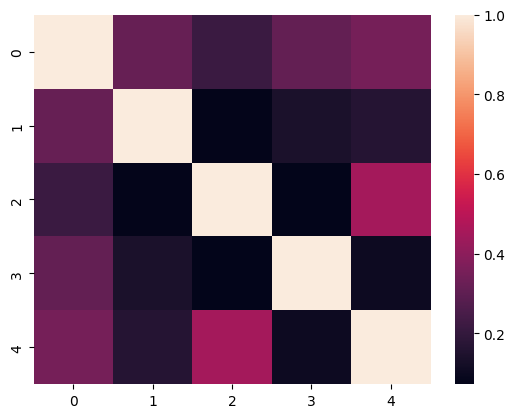

In [210]:
sns.heatmap(correlation(Y.T))

<Axes: >

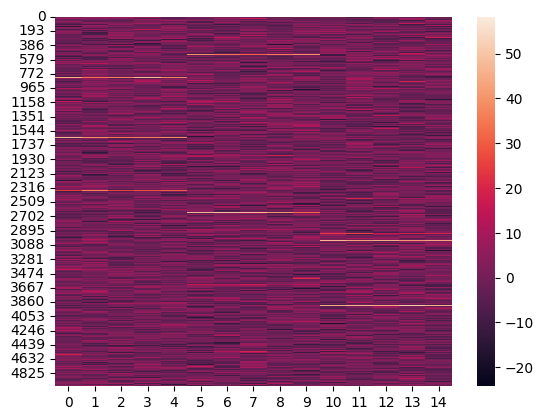

In [37]:
sns.heatmap(X)

In [38]:
X.shape

(5000, 15)

In [4]:
X, _ = generate_data(
    n_timepoints=500,
    n_components=4,
    noise=1,
    n_pixels=5,
    n_pixels_bg=0,fpl.select_adapter(fpl.enumerate_adapters()[0])
    interp_factor=1,
    firing_prop=0.1,
)

np.savetxt("./X.txt", X, delimiter=",")

In [ ]:
def nsm_offline(X, k):
    